### SmartCart - E-commerce Customer Segmentation System

#### Problem statement:-
- Smartcart e-commerce platform uses olg generic marketing and engagement strategies without clearly understanding different customer requirements.
- Due to this they loss opportunity to retain high value customer, also can not identity churn-porn users.
- They want to build a intelligent customer segmentation using ML and group together customers based on purchase behaviour, enagagement levels and loyalty indicators.

#### Dataset :-
- Smartcart has collect extensive customer data consisting of 2240 customer records and 22 attributes including demography, purchase behaviour, website activity and response.

#### My goal
- Develop this system using clustering unsupervised ML Algorithm to discover hidden patterns in customer behaviour and support data-driven decision-making for personlised marketing and customer retention.

In [1]:
import os
#os.environ[""]

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Loading dataset

In [2]:
df = pd.read_csv("smartcart_customers.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


### Understanding Dataset

- 22 features - describing customer spending and activity on platfrom
- 2240 data points/ samples represent - represnt unique customer

Understanding features(4 types):-
1. Customer Demographics:-
   - Include features:
     1. ID - unique ID for customer
     2. Year_Birth - year of birth of customer
     3. Education - highest education
     4. Maritial_Status
     5. Income - yearly household Income
     6. Kidhome - no. of small childeren in house
     7. Teenhome - no. of teenagers in house
     8. Dt_Customer - date when customer enrolled with Smartcart
         
2. Purchase Behaviour(Amt spent- how much money customer sent):-
    - Include features:
      1. MntWines - amt spent on wine products
      2. MntFruits - amt spent on fruit products
      3. MntMeatProducts - amt spent on meat products
      4. MntFishProducts - amt spent on fish products
      5. MntSweetProducts - amt spent on sweet products
      6. MntGoldProds - amt spent on gold products

3. Purchase Behaviour(Frequency- how frequently does customer make purchase):-
    - Include features:
      1. NumDealsPurchases - Purchases made using discounts
      2. NumWebPurchases - Purchases made through website
      3. NumCatalogPurchases - Purchases made through catalog
      4. NumStorePurchases -  Purchases made in physical store
      5. NumWebVisitsMonth - Number of visits to website per month

4. Customer Feedback and Constants:-
    - Includes features:
       1. Recency - Number of days since last purchase
       2. Complain - Customer complained in last 2 years (1 = Yes, 0 = No)

### Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

we can see that income column has some null value

In [4]:
df["Income"].isnull().sum()

np.int64(24)

In [5]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.009375,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.096391,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000


### Data Preprocessing

#### 1. Handle Mising values

In [6]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [7]:
df["Income"].isnull().sum()

np.int64(0)

### Feature Engineering
- Drop useless or old feature or create new features
1.  we have dates in the features in any format we need to convert this into some numerical value/meaning, here we have , Dt_Customer(date of customer joining) and Year_Birth(year of birth of customer) :-
  - we can convert this into more information feature
    1. convert Year_Birth to Age
    2. convert Dt_Customer to customer_tenure_day(from how many days has customer joined the platform - we calaculate this from the max. given date(reference date) - the customer joining date)
2. Convert all the purchase into a total spending.
3. Convert all the kids into total childern
4. Education column has a lot of categories in it and we have to convert this into fewer categories
5. Maritial status also has a lot of categories and we have to convert them into fewer categories and also give it a new column

In [8]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


- Feature - Year_Birth

In [9]:
df["Age"] = 2026 - df["Year_Birth"]

In [10]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


- feature - Dt_Customer

In [11]:
# convert the data into datatime pandas format
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

#get the reference date
ref_date = df["Dt_Customer"].max()

#new feature customer_tenure_days
df["cutomer_tenure_days"] = (ref_date - df["Dt_Customer"]).dt.days

In [12]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [13]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'cutomer_tenure_days'],
      dtype='object')

- Combine all the Purchase = MntFruits + MntWines + MntMeatProducts + MntFishProducts + MntSweetProducts +MntGoldProds

In [14]:
df["Total_spending"] = df['MntWines'] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [15]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days,Total_spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


- total children = Kidhome + Teenhome

In [16]:
df["Total_childrens"] = df["Kidhome"] + df["Teenhome"] 

In [17]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days,Total_spending,Total_childrens
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


- Education - convert 5 categories inside this features into 3 categories

In [18]:
#convert four categories in Education feature into 3
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [19]:
df["Education"] = df["Education"].replace(
    {
        "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
        "Graduation": "Graduate",
        "PhD":"Post-Graduate", "Master":"Post-Graduate"
    }
)

In [20]:
df["Education"].value_counts()

Education
Graduate         1127
Post-Graduate     856
Undergraduate     257
Name: count, dtype: int64

- Marital_Status : convert eight categories inside this feature into 2 categories

In [21]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [22]:
df["Living_with"] = df["Marital_Status"].replace(
    {
        "Married":"Couple", "Together":"Couple",
        "Divorced":"Single", "Widow":"Single", "Alone":"Single", "Absurd":"Single", "YOLO":"Single"
    }
)

In [23]:
df["Living_with"].value_counts()

Living_with
Couple    1444
Single     796
Name: count, dtype: int64

In [24]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'cutomer_tenure_days', 'Total_spending',
       'Total_childrens', 'Living_with'],
      dtype='object')

#### Drop Unneccasary Columns

In [25]:
cols_to_drop = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer", 'MntWines', 'MntFruits',
                'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
                'MntGoldProds', ]

df_cleaned = df.drop(columns=cols_to_drop)

In [26]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'cutomer_tenure_days', 'Total_spending', 'Total_childrens',
       'Living_with'],
      dtype='object')

### Visually detect outliers and remove them with the help of pairplot - which is relative plot of features.
Note: for numerical data only and select features very effectively.

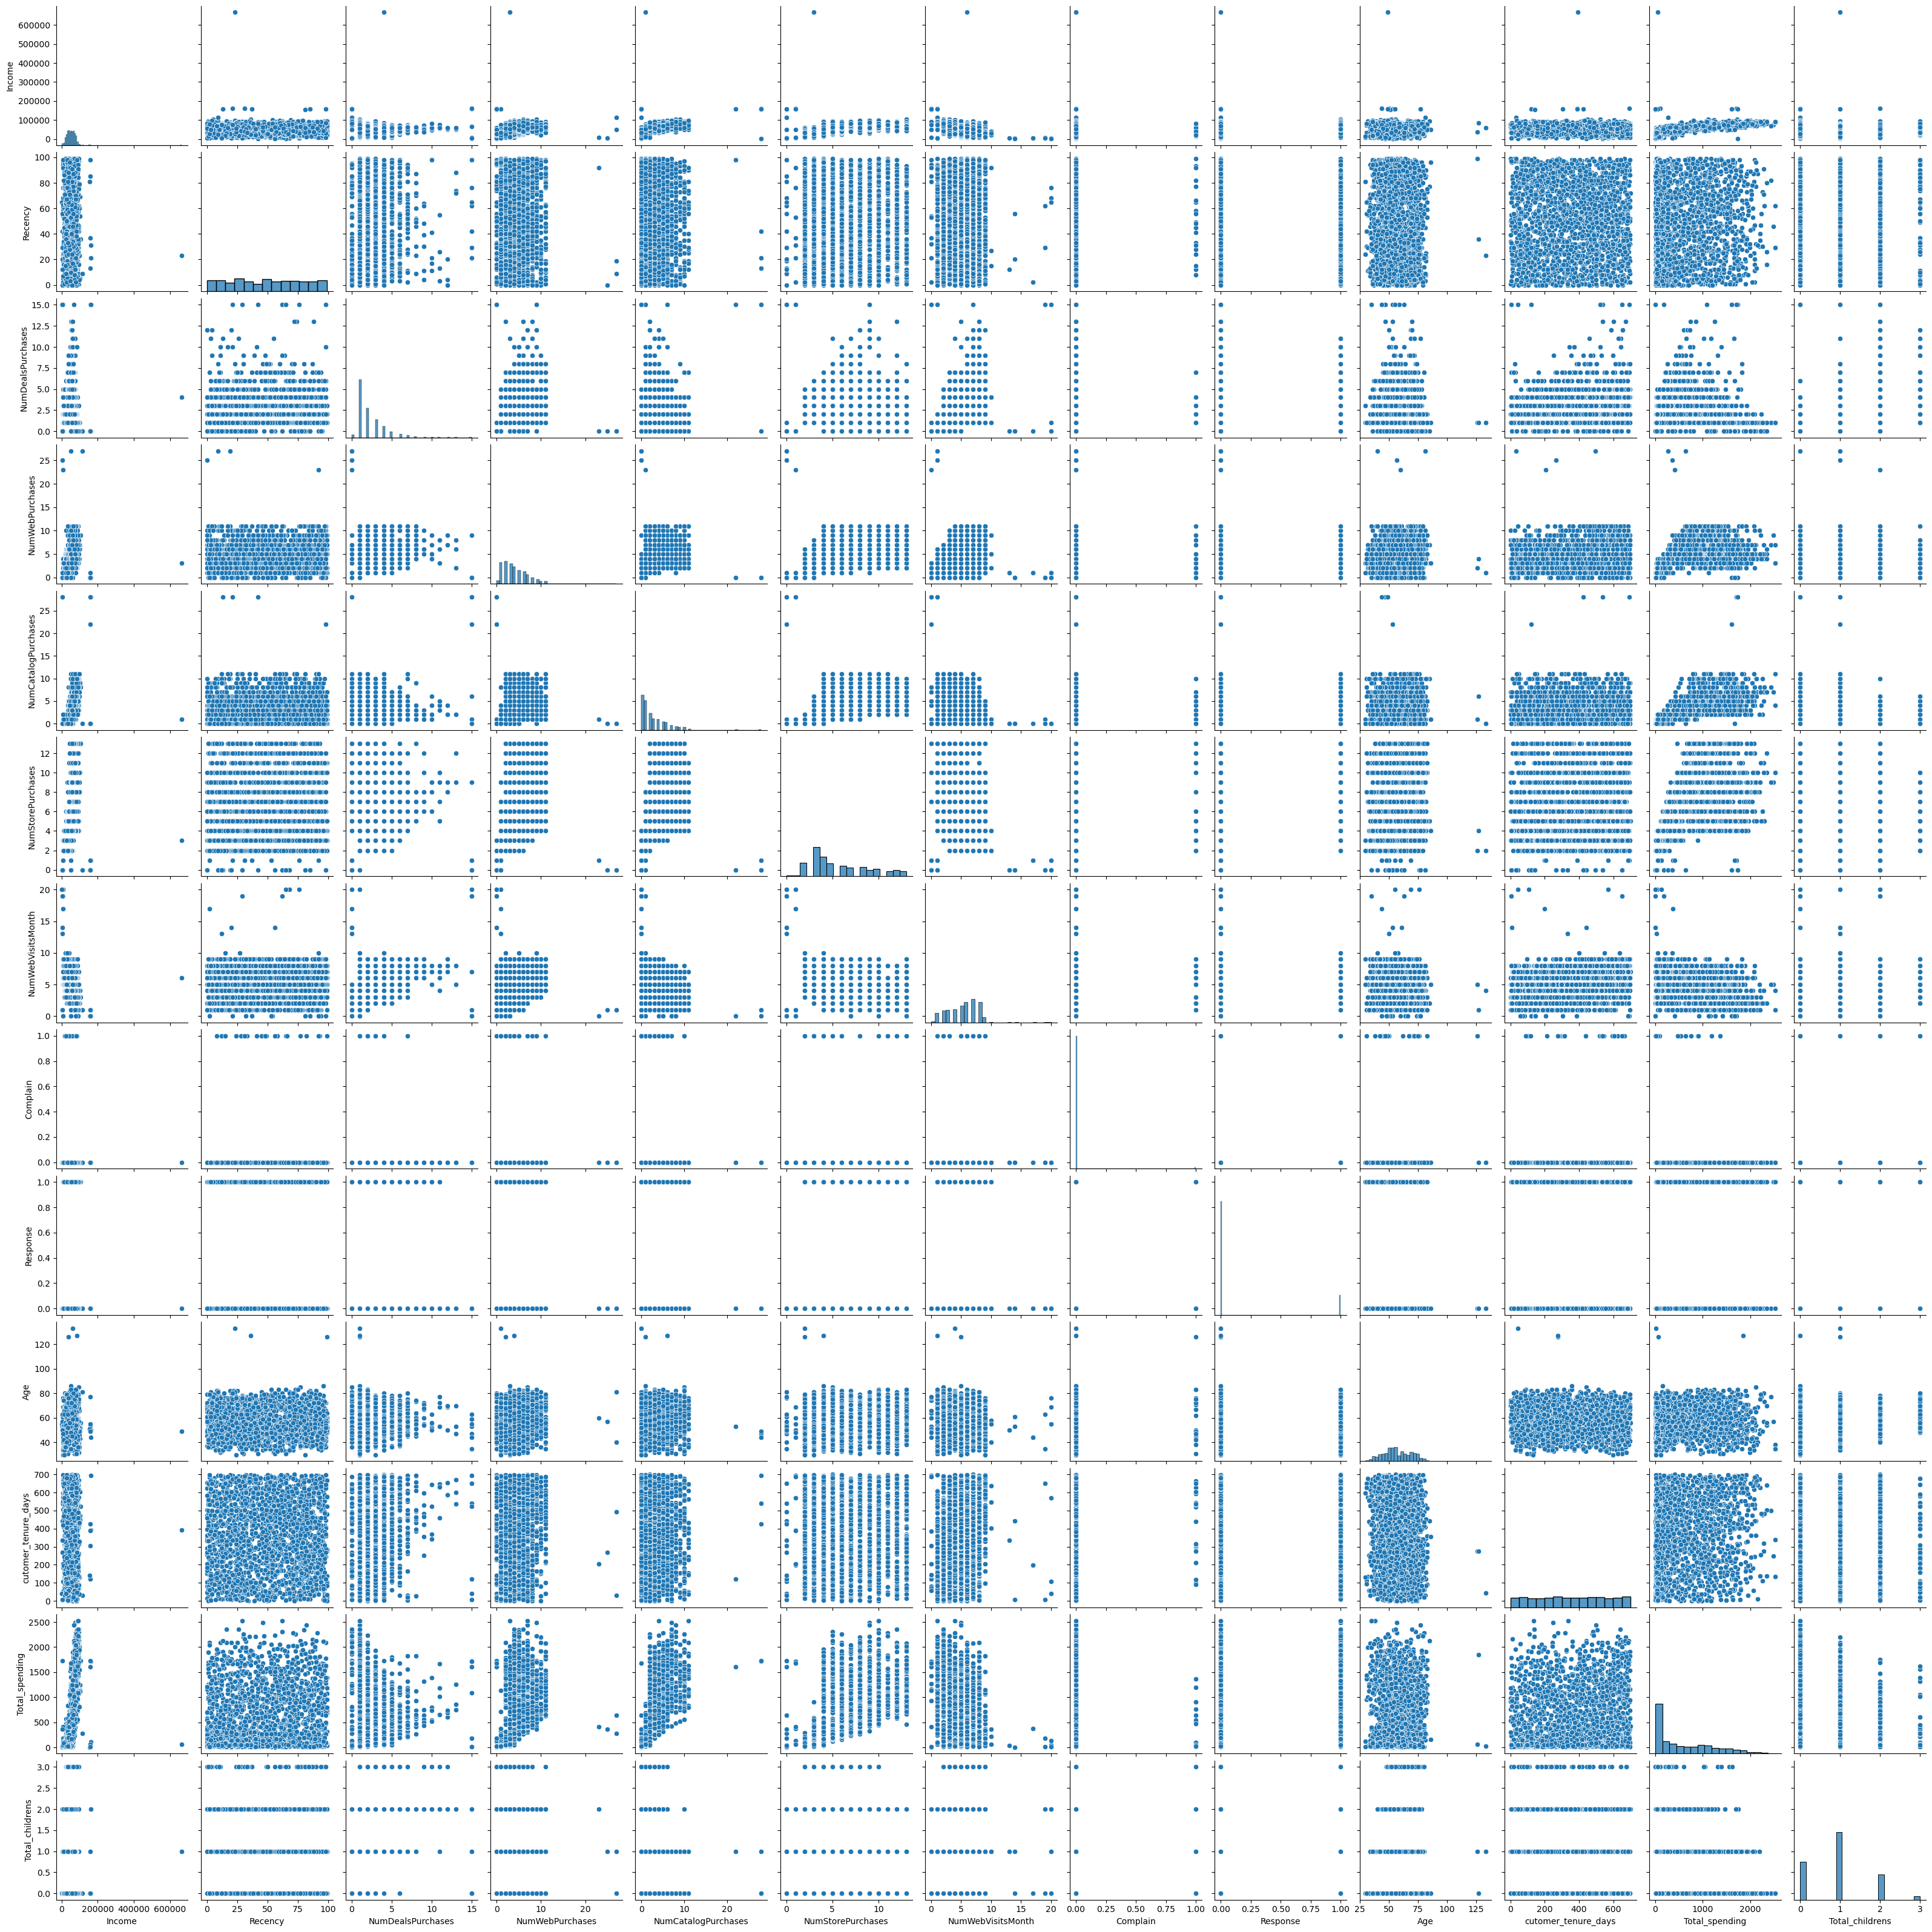

In [27]:
cols = ['Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'cutomer_tenure_days', 'Total_spending', 'Total_childrens']

sns.pairplot(df_cleaned[cols])

Outlier Detected:-
1. Income has a outlier > $600000 
2. Age has 3 outliers > 90 years
3. NumWebPurchases has 3 outliers > 20 purchases
4. NumCatalogPurchase has 3 outliers > 20 purchases
5. NumWebPurchases has few(4-5) outliers that order > 13 orders

For now, lets remove the age and income outlier

In [28]:
df_cleaned = df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned = df_cleaned[(df_cleaned["Income"]< 600_000)]

In [29]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2236 entries, 0 to 2239
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Education            2236 non-null   object 
 1   Income               2236 non-null   float64
 2   Recency              2236 non-null   int64  
 3   NumDealsPurchases    2236 non-null   int64  
 4   NumWebPurchases      2236 non-null   int64  
 5   NumCatalogPurchases  2236 non-null   int64  
 6   NumStorePurchases    2236 non-null   int64  
 7   NumWebVisitsMonth    2236 non-null   int64  
 8   Complain             2236 non-null   int64  
 9   Response             2236 non-null   int64  
 10  Age                  2236 non-null   int64  
 11  cutomer_tenure_days  2236 non-null   int64  
 12  Total_spending       2236 non-null   int64  
 13  Total_childrens      2236 non-null   int64  
 14  Living_with          2236 non-null   object 
dtypes: float64(1), int64(12), object(2)
memory 

We can see that our 4 data points have been removed here

### Correlation Using Heatmap

In [30]:
corelation_metrix = df_cleaned.corr(numeric_only=True)

corelation_metrix

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days,Total_spending,Total_childrens
Income,1.000000,0.007829,-0.107169,0.450584,0.693781,0.628075,-0.646382,-0.027871,0.161121,0.198835,-0.023677,0.789375,-0.340550
Recency,0.007829,1.000000,-0.000638,-0.010776,0.025226,0.000771,-0.021850,0.005361,-0.198781,0.019396,0.024238,0.020842,0.017826
NumDealsPurchases,-0.107169,-0.000638,1.000000,0.233971,-0.008510,0.068418,0.347216,0.003636,0.002017,0.068286,0.218009,-0.064831,0.439682
NumWebPurchases,0.450584,-0.010776,0.233971,1.000000,0.378049,0.502227,-0.056204,-0.013250,0.148390,0.153873,0.191211,0.519948,-0.146429
NumCatalogPurchases,0.693781,0.025226,-0.008510,0.378049,1.000000,0.518788,-0.520376,-0.018304,0.220813,0.125285,0.095836,0.778343,-0.439631
NumStorePurchases,0.628075,0.000771,0.068418,0.502227,0.518788,1.000000,-0.429857,-0.011563,0.038702,0.139237,0.109727,0.675460,-0.321729
NumWebVisitsMonth,-0.646382,-0.021850,0.347216,-0.056204,-0.520376,-0.429857,1.000000,0.020796,-0.004397,-0.117498,0.272105,-0.499909,0.417908
Complain,-0.027871,0.005361,0.003636,-0.013250,-0.018304,-0.011563,0.020796,1.000000,0.000167,0.004450,0.035685,-0.033784,0.031480
Response,0.161121,-0.198781,0.002017,0.148390,0.220813,0.038702,-0.004397,0.000167,1.000000,-0.018557,0.194232,0.265615,-0.169451
Age,0.198835,0.019396,0.068286,0.153873,0.125285,0.139237,-0.117498,0.004450,-0.018557,1.000000,-0.016451,0.113618,0.095512


<Axes: >

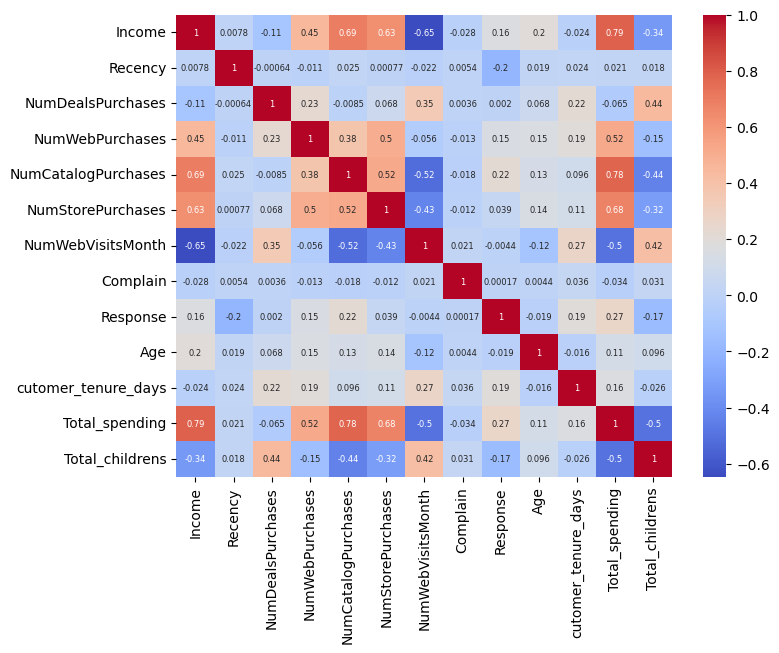

In [31]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corelation_metrix,
    cmap="coolwarm",
    annot=True,
    annot_kws={"size":6} 
)

Conclusion:-

- high positive correlation:-
  - income and Total_spending = 0.79
  - income and NumCatalogPurchases = 0.69
  - income and NumStorePurchases = 0.63
  - NumCatalogPurchases and Total_spending = 0.78
  - NumStorePurchases and Total_spending = 0.68
  - NumWebVisitsMonth and Total_spending = 0.52

  
- High negative correlation:-
  - income and NumWebVisitsMonth = -0.65
  - NumCatalogPurchases and NumWebVisitsMonth = -0.52
  - Total_spending and NumWebVisitsMonth = -0.5
  - Total_spending and Total_childrens = -0.5

In [32]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2236 entries, 0 to 2239
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Education            2236 non-null   object 
 1   Income               2236 non-null   float64
 2   Recency              2236 non-null   int64  
 3   NumDealsPurchases    2236 non-null   int64  
 4   NumWebPurchases      2236 non-null   int64  
 5   NumCatalogPurchases  2236 non-null   int64  
 6   NumStorePurchases    2236 non-null   int64  
 7   NumWebVisitsMonth    2236 non-null   int64  
 8   Complain             2236 non-null   int64  
 9   Response             2236 non-null   int64  
 10  Age                  2236 non-null   int64  
 11  cutomer_tenure_days  2236 non-null   int64  
 12  Total_spending       2236 non-null   int64  
 13  Total_childrens      2236 non-null   int64  
 14  Living_with          2236 non-null   object 
dtypes: float64(1), int64(12), object(2)
memory 

### Feature Encoding and Scaling our data

In [33]:
# feature encoding is needed on categorical features
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["Living_with","Education"]

ohe = OneHotEncoder() # we do not give dropfirst=True because in clustering we do not have any multilinearity problem, and doing this True might loss some meaning ful information to form clusters

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

#convert this sparce matrix into a datafram
enc_df_cols = pd.DataFrame(enc_cols.toarray(), columns= ohe.get_feature_names_out(cat_cols), index=df_cleaned.index) 

In [34]:
#concatinate enc_df_cols to df_cleaned and remove old cols
df_encoded = pd.concat((df_cleaned.drop(columns=cat_cols,axis=1),enc_df_cols), axis=1)
df_encoded

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days,Total_spending,Total_childrens,Living_with_Couple,Living_with_Single,Education_Graduate,Education_Post-Graduate,Education_Undergraduate
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,0.0,1.0,1.0,0.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,0.0,1.0,1.0,0.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,1.0,0.0,0.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,1.0,0.0,0.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,1.0,0.0,1.0,0.0,0.0
2236,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,1.0,0.0,0.0,1.0,0.0
2237,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,0.0,1.0,1.0,0.0,0.0
2238,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,1.0,0.0,0.0,1.0,0.0


### Scaling

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = df_encoded
X_scaled= scaler.fit_transform(X)
X_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ...,  0.99286978,
        -0.78683962, -0.35877969],
       [-0.262003  , -0.38397129, -0.16869955, ...,  0.99286978,
        -0.78683962, -0.35877969],
       [ 0.91842301, -0.7984675 , -0.68613742, ...,  0.99286978,
        -0.78683962, -0.35877969],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ...,  0.99286978,
        -0.78683962, -0.35877969],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -1.00718142,
         1.27090703, -0.35877969],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -1.00718142,
         1.27090703, -0.35877969]], shape=(2236, 18))

### Visualize data using PCA 

In [36]:
X.shape

(2236, 18)

In [37]:
# we have to do PCA from 18 dimensions to 2 dimension and 3 dimension to visualize our data.
from sklearn.decomposition import PCA

#2d
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

In [38]:
pca_2d.explained_variance_ratio_

array([0.23163158, 0.11385454])

- here we can only capute 0.23 + 0.11 = 0.34 info. 

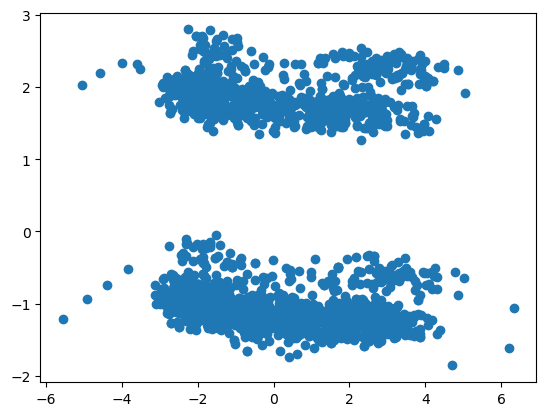

In [39]:
#visualize
plt.scatter(X_pca_2d[:, 0],X_pca_2d[:, 1])

In [40]:
# 3d - to capture more info/variance

pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)
pca_3d.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

3d varience captured = 0.44

Text(0.5, 0, 'PCA1')

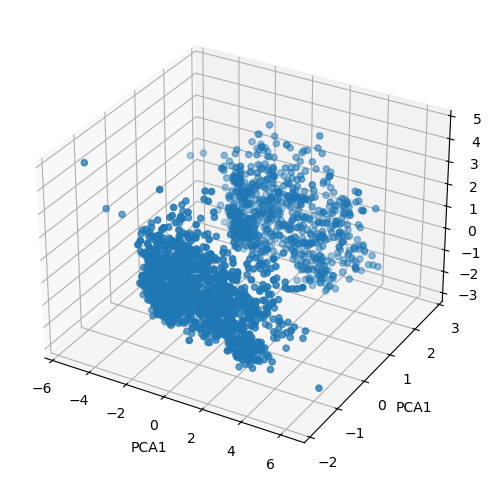

In [41]:
#visualize
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca_3d[:, 0],X_pca_3d[:, 1],X_pca_3d[:, 2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA1")
ax.set_xlabel("PCA1")

- As this dataset is not for anamoly detection I am going to compare 2 algorithm.
- KMeans and agglomerative clustering

### K-Means

#### Choosing K - Elbow method

In [42]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [43]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

#Try k from 1 to 10
K = range(1,10)
wcss = []

for k in K:
    #compute KMeans algo for all K
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(X_pca_3d)
    wcss.append(kmeans.inertia_)

C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

In [44]:
knee = KneeLocator(K, wcss, curve="convex", direction="decreasing")
optimal_k = knee.elbow
print("Best k = ",optimal_k)

Best k =  4


Text(0, 0.5, 'wcss value')

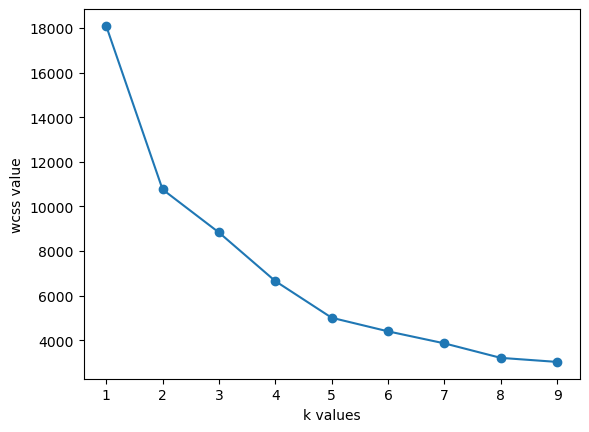

In [45]:
plt.plot(K,wcss, marker="o",)
plt.xlabel("k values")
plt.ylabel("wcss value")

#### Choosing K using silhouette_score

In [46]:
from sklearn.metrics import silhouette_score

In [47]:
s_score = []
K = range(2,10)
for k in K:
    #compute KMeans algo for all K
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca_3d)
    score = silhouette_score(X_pca_3d,labels)
    s_score.append(score)

C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

Text(0, 0.5, 's_score value')

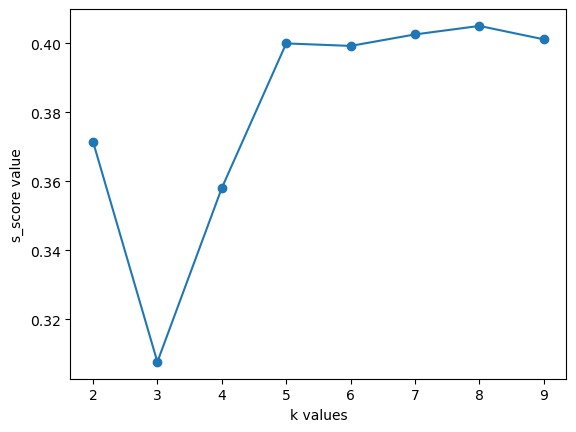

In [48]:
plt.plot(K,s_score, marker="o",)
plt.xlabel("k values")
plt.ylabel("s_score value")

#### combine both grahh into one:-

Text(0, 0.5, 's_score')

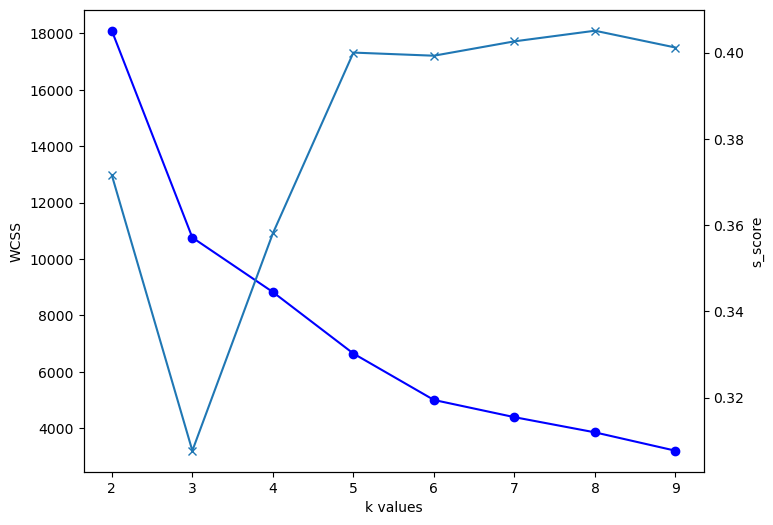

In [49]:
fig, ax1 = plt.subplots(figsize =(8,6))
ax1.plot(K, wcss[:len(K)], marker="o", color="blue")
ax1.set_xlabel("k values")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(K, s_score[:len(K)], marker = "x")
ax2.set_ylabel("s_score")

Conclusion:-
k=4 is the optimal k we got from both methods(elbow and silhouette_score)

### Clustring Algorithm - Kmeans

In [50]:
kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X_pca_3d)

C:\Users\patel\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


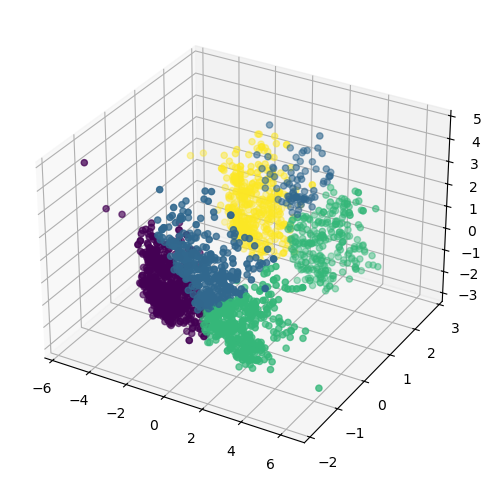

In [51]:
#visualize
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca_3d[:, 0],X_pca_3d[:, 1],X_pca_3d[:, 2], c=labels_kmeans)

### Clustering - Agglomarative Clustering

In [52]:
from sklearn.cluster import AgglomerativeClustering

agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca_3d)

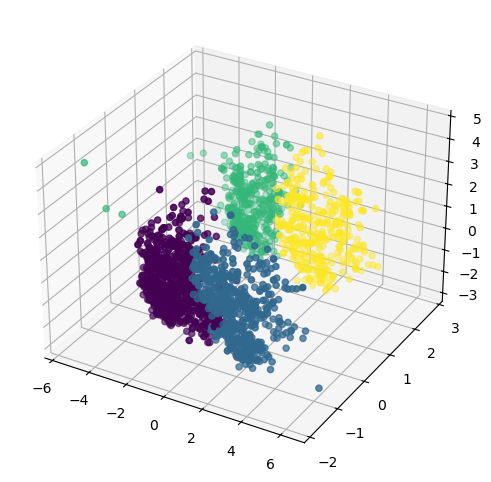

In [53]:
#visualize
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca_3d[:, 0],X_pca_3d[:, 1],X_pca_3d[:, 2], c=labels_agg)

Conclusion:- visually agglomarative clusters are formed better than Kmeans clusters. 
Therefore we will use agglomerative cluster to do profiling/characterization of clusters to identify customer profil in that cluster

### Characterization of clusters:
- we will add this new labels(which are cluster) into out df_cleaned dataframe and plot and check the relationship we had from the correlation-metrix

In [55]:
X["cluster"] = labels_agg
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,cutomer_tenure_days,Total_spending,Total_childrens,Living_with_Couple,Living_with_Single,Education_Graduate,Education_Post-Graduate,Education_Undergraduate,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,0.0,1.0,1.0,0.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,0.0,1.0,1.0,0.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,1.0,0.0,0.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,1.0,0.0,0.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,1.0,0.0,0.0,1.0,0.0,0


<Axes: xlabel='cluster', ylabel='count'>

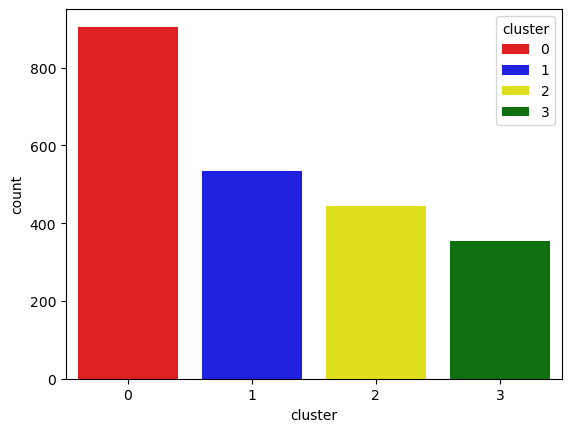

In [57]:
#lets see how many customers in each clusters
color_palat = ["red","blue","yellow","green"]

sns.countplot(x=X["cluster"], palette=color_palat, hue=X["cluster"])

<Axes: xlabel='Total_spending', ylabel='Income'>

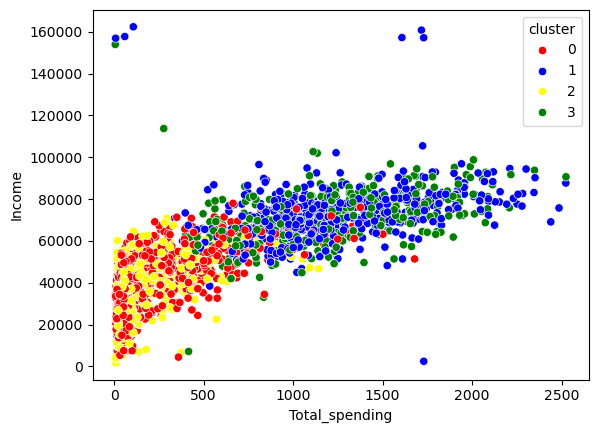

In [61]:
#lets compare some correlation feature we found through correlation metrix

#income and total_spending
sns.scatterplot(x=X["Total_spending"], y=X["Income"],palette=color_palat, hue=X["cluster"])

Information Derived:-

- Cluster 0 (Red):
  - income high / moderate
  - spending high / moderate
- Cluster 1 (Blue)
  - income high
  - spending high
- Cluster 2 (Yellow):
  - income low
  - spending low
- Cluster 3 (Green):
  - income high/moderate
  - spending high
<br></br>
- premium customer = cluster 1 and cluster 3
- price_sensitive customers = cluster 0 and cluster 12

#### Cluster Summary:-
- we can get more info about clusters using Cluster summary by taking mean of every features for every clusters

In [63]:
cluster_summery = X.groupby(X["cluster"]).mean()
print("cluster_summery: \n",cluster_summery)

cluster_summery: 
                Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  cutomer_tenure_days  Total_spending  

#### Explaining final decision from cluster summary - Meaningful Insights
- cluster 0
  - children more
  - age low
  - Web purchase low
  - Catalog Purchases low
  - StorePurchases low
  - Web Visits Month more
  - Response very less
  - couple
  - This customers are family shoppers we can offer discounts/coupuns/sales

- cluster 1
  - children fewer
  - age high
  - Web purchase high
  - Catalog Purchases high
  - StorePurchases high
  - Web Visits Month low
  - Response avg
  - couple
  - This customer are premium customers - we can offer loyalty programs
- cluster 2
  - children more
  - age low
  - Web purchase very low
  - Catalog Purchases very low
  - StorePurchases very low
  - Web Visits Month more
  - Response a little
  - Single
  - This customers are digital customers donot purchase more we can consider them for sales
- cluster 3
  - children fewer
  - age high
  - Web purchase high
  - Catalog Purchases high
  - StorePurchases high
  - Web Visits Month low
  - Response best
  - Single
  - This are High value premium customers and we can give very premium / personalised services to them.
